# Этап 3. Предобработка данных

**Проект:** качество жизни в регионах Казахстана, 2015–2024
**Вход:** база `data/regions_kz.db` (этап 2, представления `v_panel_regions` и `v_panel_units`)
**Выход:** `data/processed/panel_regions_clean.csv`, `data/processed/panel_units_clean.csv`

> Перед запуском выполните из корня проекта `python src/build_db.py` и `python src/run_queries.py`.

## Оглавление
1. [Настройка](#setup)
2. [Загрузка из SQLite](#load)
3. [Типы данных](#types)
4. [Дубликаты](#dups)
5. [Пропуски](#missing)
6. [Логические проверки](#logic)
7. [Население: начало года, конец года, среднегодовое](#population)
8. [Пересчёт показателей на душу населения](#percapita)
9. [Аномалии](#anomalies)
10. [Флаги разрывов в рядах](#flags)
11. [До и после очистки](#before-after)
12. [Выводы этапа](#summary)

<a id="setup"></a>
## 1. Настройка

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b4b2a9",
    "grid.color": "#e6e4dd",
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

BLUE, ORANGE, GRAY, INK = "#2a78d6", "#eb6834", "#b4b2a9", "#52514e"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = ROOT / "data" / "regions_kz.db"
OUT = ROOT / "data" / "processed"

con = sqlite3.connect(DB_PATH)
print(f"База: {DB_PATH.relative_to(ROOT)}")

База: data/regions_kz.db


<a id="load"></a>
## 2. Загрузка из SQLite

Берём две панели из представлений этапа 2:
- **`regions`** — регионы в границах своего года (для карт и срезов 2022–2024);
- **`units`** — 16 сопоставимых единиц в границах до 2018 г. (для динамики и регрессии).

Параллельно ведём журнал `log`: сколько строк, столбцов и пропусков после каждого шага.

In [2]:
regions = pd.read_sql("SELECT * FROM v_panel_regions", con)
units = pd.read_sql("SELECT * FROM v_panel_units", con)

# Представления должны быть созданы актуальной версией sql/queries.sql
NEED = {"investments_thous", "grp_mln", "housing_thous_m2", "doctors"}
missing_cols = NEED - set(regions.columns)
assert not missing_cols, (
    f"В представлениях нет столбцов {sorted(missing_cols)}. Замените sql/queries.sql на новую версию "
    "и выполните из корня проекта: python src/run_queries.py, затем перезапустите ноутбук.")

log = []

def track(step: str) -> None:
    for name, df in [("regions", regions), ("units", units)]:
        log.append({"шаг": step, "набор": name, "строк": len(df),
                    "столбцов": df.shape[1], "пропусков": int(df.isna().sum().sum())})

track("0. загрузка")
print(f"regions: {regions.shape[0]} строк × {regions.shape[1]} столбцов, "
      f"{regions.region_id.nunique()} регионов, {regions.year.min()}–{regions.year.max()}")
print(f"units:   {units.shape[0]} строк × {units.shape[1]} столбцов, "
      f"{units.unit_id.nunique()} единиц, {units.year.min()}–{units.year.max()}")

regions: 176 строк × 26 столбцов, 21 регионов, 2015–2024
units:   160 строк × 24 столбцов, 16 единиц, 2015–2024


<a id="types"></a>
## 3. Типы данных

SQLite хранит флаг `is_resource` как число, а макрорегион как текст. Приводим к типам, с которыми удобнее работать: логический флаг, категория для группировок, целые числа для идентификаторов и года.

In [3]:
def fix_types(df: pd.DataFrame, id_col: str) -> pd.DataFrame:
    return df.astype({
        id_col: "int16",
        "year": "int16",
        "is_resource": "bool",
        "macro_region": "category",
    })

before = regions.dtypes.astype(str).value_counts().to_dict()
regions = fix_types(regions, "region_id").astype({"unit_id": "int16"})
units = fix_types(units, "unit_id")
after = regions.dtypes.astype(str).value_counts().to_dict()

print(f"Типы до:    {before}")
print(f"Типы после: {after}")
track("1. типы")

Типы до:    {'float64': 18, 'int64': 4, 'str': 3, 'object': 1}
Типы после: {'float64': 18, 'int16': 3, 'str': 2, 'category': 1, 'bool': 1, 'object': 1}


<a id="dups"></a>
## 4. Дубликаты

Ключ панели — пара «регион × год». В базе на неё стоит первичный ключ, поэтому дублей быть не должно, но проверяем: ошибка в SQL-джойне могла бы размножить строки.

In [4]:
for name, df, keys in [("regions", regions, ["region_id", "year"]),
                       ("units", units, ["unit_id", "year"])]:
    full = df.duplicated().sum()
    by_key = df.duplicated(keys).sum()
    print(f"{name:<8} полных дублей: {full}, дублей по ключу {keys}: {by_key}")

regions = regions.drop_duplicates(["region_id", "year"])
units = units.drop_duplicates(["unit_id", "year"])
track("2. дубликаты")

regions  полных дублей: 0, дублей по ключу ['region_id', 'year']: 0
units    полных дублей: 0, дублей по ключу ['unit_id', 'year']: 0


**Вывод:** дублей нет. JOIN-ы на этапе 2 не размножили строки.

<a id="missing"></a>
## 5. Пропуски

In [5]:
def missing_table(df: pd.DataFrame) -> pd.DataFrame:
    m = df.isna().sum()
    m = m[m > 0]
    return pd.DataFrame({"пропусков": m, "доля, %": (m / len(df) * 100).round(1)})

pd.concat({"regions": missing_table(regions), "units": missing_table(units)}, names=["набор", "столбец"])

пропусков  доля, %
набор   столбец                          
regions name_en                3      1.7
        education_low        176    100.0
units   education_low        160    100.0

**Что видно:**
- `education_low` пуст полностью: в Талдау доля рабочей силы по уровню образования публикуется только по стране. Столбец удаляем, в README это записано как ограничение.
- `name_en` пуст у Южно-Казахстанской области (2015–2017): после 2018 г. такого региона нет, на современной карте у него нет границ. Это не ошибка.
- В остальных столбцах пропусков нет. Структурные пропуски (например, области Абай в 2019 г. ещё не было) отсечены ещё в SQL через `v_region_years`.

**Почему не применяем `fillna()` к данным:** заполнять пропуски средним или интерполяцией здесь значило бы выдумывать статистику. Единственный пропуск, который можно заполнить без искажений, — пустое английское название ЮКО: подставляем описательную подпись, чтобы в таблицах не было `NaN`.

In [6]:
regions = regions.drop(columns="education_low")
units = units.drop(columns="education_low")
regions["name_en"] = regions["name_en"].fillna("South Kazakhstan Region (until 2018)")

track("3. пропуски")
print(f"Осталось пропусков: regions — {regions.isna().sum().sum()}, units — {units.isna().sum().sum()}")

Осталось пропусков: regions — 0, units — 0


<a id="logic"></a>
## 6. Логические проверки

«Если в данных всё идеально — ищи подвох». Проверяем, что значения физически возможны и согласованы между собой.

In [7]:
RULES = [
    ("население > 0",                       lambda d: d.population > 0),
    ("доход на душу > 0",                    lambda d: d.income_pc > 0),
    ("доход выше прожиточного минимума",     lambda d: d.income_to_subsistence > 1),
    ("зарплата выше дохода на душу",         lambda d: d.wage > d.income_pc),
    ("безработица от 0 до 100%",             lambda d: d.unemployment.between(0, 100)),
    ("бедность от 0 до 100%",                lambda d: d.poverty.between(0, 100)),
    ("неформальная занятость от 0 до 100%",  lambda d: d.informal_share.between(0, 100)),
    ("продолжительность жизни 60–85 лет",    lambda d: d.life_expectancy.between(60, 85)),
    ("врачей больше 0",                      lambda d: d.doctors > 0),
    ("инвестиции и ВРП больше 0",            lambda d: (d.investments_thous > 0) & (d.grp_mln > 0)),
]

checks = pd.DataFrame(
    [(rule, int((~fn(df)).sum())) for rule, fn in RULES for df in [regions]],
    columns=["правило", "нарушений (regions)"],
)
checks["нарушений (units)"] = [int((~fn(units)).sum()) for _, fn in RULES]
checks

,правило,нарушений (regions),нарушений (units)
0,население > 0,0,0
1,доход на душу > 0,0,0
2,доход выше прожиточного минимума,0,0
3,зарплата выше дохода на душу,0,0
4,безработица от 0 до 100%,0,0
5,бедность от 0 до 100%,0,0
6,неформальная занятость от 0 до 100%,0,0
7,продолжительность жизни 60–85 лет,0,0
8,врачей больше 0,0,0
9,инвестиции и ВРП больше 0,0,0


In [8]:
# Сумма 16 единиц должна совпадать с итогом по стране (запрос q10 этапа 2)
q10 = pd.read_csv(OUT / "q10_check_units_vs_country.csv")
print(f"Расхождение с итогом по РК, макс.: "
      f"население {abs(q10.population_pct - 100).max():.2f}%, "
      f"инвестиции {abs(q10.investments_pct - 100).max():.2f}%, "
      f"ВРП {abs(q10.grp_pct - 100).max():.2f}%")

Расхождение с итогом по РК, макс.: население 0.00%, инвестиции 0.00%, ВРП 0.00%


**Вывод:** все значения в допустимых пределах, сумма регионов сходится с итогом по стране. Проверка «зарплата выше дохода на душу» тоже проходит везде: доход на душу делится и на неработающих (детей, пенсионеров), поэтому он должен быть ниже зарплаты.

<a id="population"></a>
## 7. Население: начало года, конец года, среднегодовое

На этапе 2 все показатели «на душу» делились на население **на начало года**. Это неточно:
- инвестиции, ВРП и ввод жилья — **потоки за год**, их принято делить на **среднегодовое** население;
- число врачей дано **на конец года**, его логично делить на население на конец года (= начало следующего).

Проверим гипотезу на официальном показателе «врачей на 10 тыс.»: какое население даёт совпадение?

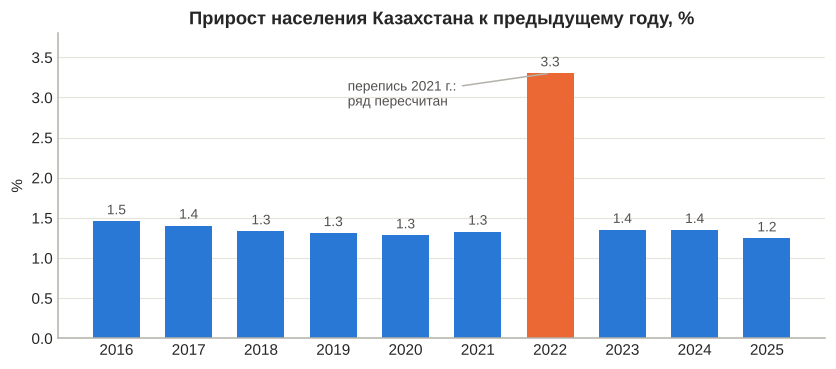

In [9]:
pop = pd.read_sql("""
    SELECT o.region_id, r.unit_id, o.year, o.value AS pop_start
    FROM observations AS o
    JOIN regions AS r ON r.region_id = o.region_id
    WHERE o.indicator_code = 'population' AND o.value IS NOT NULL
""", con)

kz = pop[pop.region_id == 0].set_index("year").pop_start
kz_growth = (kz.pct_change() * 100).dropna()

fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [ORANGE if y == 2022 else BLUE for y in kz_growth.index]
ax.bar(kz_growth.index, kz_growth.values, color=colors, width=0.65)
for y, v in kz_growth.items():
    ax.text(y, v + 0.05, f"{v:.1f}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_title("Прирост населения Казахстана к предыдущему году, %")
ax.set_ylabel("%")
ax.set_ylim(0, kz_growth.max() * 1.15)
ax.set_xticks(kz_growth.index)
ax.grid(axis="x", visible=False)
ax.annotate("перепись 2021 г.:\nряд пересчитан", xy=(2022, kz_growth[2022]),
            xytext=(2019.2, 2.9), color=INK, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=GRAY))
plt.show()

**Вывод:** обычный прирост населения — 1,3–1,5% в год, а на 1 января 2022 г. — 3,3%. Это не демографический всплеск, а пересчёт численности по итогам переписи 2021 г. Значит, в рядах «на душу населения» между 2021 и 2022 гг. есть **методологический разрыв**: часть «роста» или «падения» показателей на душу в 2022 г. объясняется сменой базы. Отметим это флагом в разделе 10.

In [10]:
# Население на конец года = на начало следующего, в тех же границах.
# В год перед реформой границ «следующее начало» уже в новых границах — там его не берём.
BORDER_CHANGE = {(51, 2017), (19, 2021), (35, 2021), (63, 2021)}

pop = pop.sort_values(["region_id", "year"])
pop["pop_end"] = pop.groupby("region_id").pop_start.shift(-1)
same_borders = ~pop.set_index(["region_id", "year"]).index.isin(list(BORDER_CHANGE))
pop["pop_end"] = pop.pop_end.where(same_borders)
pop["pop_avg"] = pop[["pop_start", "pop_end"]].mean(axis=1)   # без pop_end → берётся начало года

official = pd.read_sql(
    "SELECT region_id, year, value AS official FROM observations "
    "WHERE indicator_code = 'doctors_per10k' AND value IS NOT NULL AND region_id <> 0", con)

chk = (regions[["region_id", "region", "year", "doctors"]]
       .merge(pop, on=["region_id", "year"])
       .merge(official, on=["region_id", "year"]))

compare = []
for basis, col in [("начало года", "pop_start"), ("среднегодовое", "pop_avg"), ("конец года", "pop_end")]:
    calc = chk.doctors / chk[col] * 1e4
    err = (calc - chk.official).abs()
    compare.append({"население": basis, "MAE": round(err.mean(), 2),
                    "доля совпадений (|ошибка| ≤ 0,5)": f"{(err <= 0.5).mean():.0%}",
                    "макс. ошибка": round(err.max(), 1)})
pd.DataFrame(compare)

,население,MAE,"доля совпадений (|ошибка| ≤ 0,5)",макс. ошибка
0,начало года,0.75,57%,9.2
1,среднегодовое,0.43,71%,4.3
2,конец года,0.32,90%,2.9


**Вывод:** с населением на конец года наш расчёт совпадает с официальным (с точностью до округления БНС до целых) в 9 случаях из 10. Значит, БНС делит число врачей на население на конец года. Расхождение у Астаны на этапе 2 объяснялось именно этим: город растёт на 4–7% в год, и разница между началом и концом года заметна.

**Решение:**
- врачи на 10 тыс. → население **на конец года**;
- инвестиции, ВРП, ввод жилья на душу → **среднегодовое** население.

<a id="percapita"></a>
## 8. Пересчёт показателей на душу населения

In [11]:
def add_per_capita(df: pd.DataFrame, p: pd.DataFrame, key: str) -> pd.DataFrame:
    df = df.merge(p[[key, "year", "pop_avg", "pop_end"]], on=[key, "year"], how="left")
    end = df.pop_end.fillna(df.population)        # нет конца года → начало года
    df["investments_pc"] = (df.investments_thous * 1_000 / df.pop_avg).round()
    df["grp_pc"] = (df.grp_mln * 1_000_000 / df.pop_avg).round()
    df["housing_m2_per1000"] = (df.housing_thous_m2 * 1_000_000 / df.pop_avg).round(1)
    df["doctors_per10k"] = (df.doctors * 10_000 / end).round(1)
    return df

# Население единиц: сумма регионов. Границы единиц не менялись — переход на конец года безопасен.
pop_units = pop[pop.unit_id.notna()].groupby(["unit_id", "year"], as_index=False).pop_start.sum()
pop_units["unit_id"] = pop_units.unit_id.astype("int16")
pop_units = pop_units.sort_values(["unit_id", "year"])
pop_units["pop_end"] = pop_units.groupby("unit_id").pop_start.shift(-1)
pop_units["pop_avg"] = pop_units[["pop_start", "pop_end"]].mean(axis=1)

old = units[["investments_pc", "grp_pc", "housing_m2_per1000", "doctors_per10k"]].copy()
regions = add_per_capita(regions, pop[pop.region_id != 0], "region_id")
units = add_per_capita(units, pop_units, "unit_id")

ratio = (units[old.columns] / old - 1) * 100
shift = ratio.agg(["mean", "min", "max"]).T.round(2)
shift.columns = ["средний сдвиг, %", "мин., %", "макс., %"]
track("4. пересчёт на душу")
ext = units.assign(сдвиг=ratio.investments_pc)[["unit_name", "year", "сдвиг"]]
print("Сильнее всего изменились (инвестиции на душу, %):")
print(pd.concat([ext.nsmallest(2, "сдвиг"), ext.nlargest(2, "сдвиг")]).round(2).to_string(index=False))
shift

Сильнее всего изменились (инвестиции на душу, %):
           unit_name  year  сдвиг
           г. Астана  2016  -5.43
           г. Астана  2021  -4.49
        Костанайская  2021   1.70
Северо-Казахстанская  2024   0.75


,"средний сдвиг, %","мин., %","макс., %"
investments_pc,-0.65,-5.43,1.70
grp_pc,-0.65,-5.43,1.70
housing_m2_per1000,-0.64,-5.43,1.70
doctors_per10k,-1.25,-10.31,3.51


**Вывод:** в среднем показатели на душу снизились на 0,6–1,3%, потому что население в целом растёт и среднегодовое больше, чем на начало года. Но поправка неравномерна: у Астаны показатели снизились до −5% (в 2016 и 2021 гг. её население за год выросло на 11,5% и 9,4%), а врачи на 10 тыс. в 2016 г. — на 10%. У Костанайской и Северо-Казахстанской областей, где население убывает, показатели наоборот немного выросли (до +1,7%). Без поправки столица выглядела бы «богаче», а север — «беднее», чем на самом деле.

<a id="anomalies"></a>
## 9. Аномалии

Ищем резкие изменения год к году (больше ±35%) на **сопоставимой** панели `units`. На панели `regions` такие скачки дают реформы границ: например, доход ВКО в 2022 г. «вырос» на 37%, потому что из неё выделили более бедную область Абай.

Рост дохода в 2022 г.: в границах года 37.3%, сопоставимо 22.3%


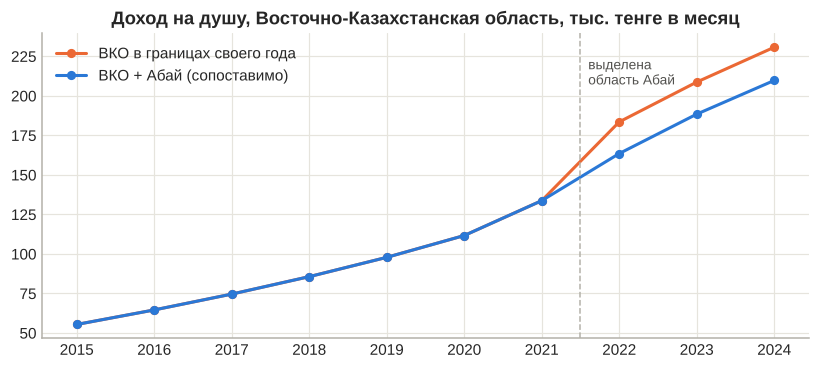

In [12]:
vko = (regions[regions.region_id.isin([63])][["year", "income_pc"]]
       .merge(units[units.unit_id == 63][["year", "income_pc"]], on="year", suffixes=("_reg", "_unit")))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(vko.year, vko.income_pc_reg / 1000, color=ORANGE, lw=2, marker="o", ms=5, label="ВКО в границах своего года")
ax.plot(vko.year, vko.income_pc_unit / 1000, color=BLUE, lw=2, marker="o", ms=5, label="ВКО + Абай (сопоставимо)")
ax.axvline(2021.5, color=GRAY, lw=1, ls="--")
ax.text(2021.6, vko.income_pc_reg.max() / 1000 * 0.97, "выделена\nобласть Абай", color=INK, fontsize=9, va="top")
ax.set_title("Доход на душу, Восточно-Казахстанская область, тыс. тенге в месяц")
ax.set_xticks(vko.year)
ax.legend(frameon=False, loc="upper left")
plt.show()

jump = vko.set_index("year").pct_change().loc[2022] * 100
print(f"Рост дохода в 2022 г.: в границах года {jump.income_pc_reg:.1f}%, сопоставимо {jump.income_pc_unit:.1f}%")

**Вывод:** из 37% «роста» ВКО в 2022 г. около 15 п. п. — эффект состава (ушла более бедная область Абай), а не рост доходов. Поэтому динамику и регрессию считаем на панели `units`, а `regions` используем для срезов 2022–2024.

In [13]:
METRICS = {
    "income_pc": "доход на душу", "wage": "зарплата", "investments_pc": "инвестиции на душу",
    "grp_pc": "ВРП на душу", "housing_m2_per1000": "ввод жилья", "doctors_per10k": "врачи на 10 тыс.",
    "poverty": "бедность", "informal_share": "неформальная занятость", "life_expectancy": "продолжительность жизни",
}
units = units.sort_values(["unit_id", "year"])
rows = []
for col, label in METRICS.items():
    chg = units.groupby("unit_id")[col].pct_change() * 100
    big = units.loc[chg.abs() > 35, ["unit_name", "year"]].assign(показатель=label, изменение=chg[chg.abs() > 35].round(1))
    rows.append(big)
jumps = pd.concat(rows)
summary = jumps.groupby("показатель").agg(скачков=("year", "size"),
                                          годы=("year", lambda s: ", ".join(map(str, sorted(set(s))))))
summary.sort_values("скачков", ascending=False)

,скачков,годы
показатель,,
бедность,19,"2018, 2020, 2021, 2022"
неформальная занятость,17,"2016, 2017, 2018, 2019, 2021, 2022, 2024"
инвестиции на душу,9,"2016, 2018, 2019, 2020, 2023, 2024"
ввод жилья,8,"2017, 2018, 2019, 2020, 2023"


In [14]:
# Бедность: скачок 2018 г. сразу во всех регионах
pov = units.pivot_table(index="year", values="poverty", aggfunc="median")
print("Медиана доли бедных по 16 единицам, %:")
print(pov.T.round(1).to_string(index=False))
p18 = units.pivot(index="unit_id", columns="year", values="poverty")
g18 = (p18[2018] / p18[2017] - 1) * 100
print(f"\n2018 к 2017: рост доли бедных в {(g18 > 0).sum()} из {len(g18)} единиц, "
      f"больше чем на 35% — в {(g18 > 35).sum()}; разброс {g18.min():+.0f}…{g18.max():+.0f}%")
print("\nСкачки инвестиций и ввода жилья:")
print(jumps[jumps.показатель.isin(["инвестиции на душу", "ввод жилья"])]
      .sort_values(["показатель", "изменение"]).to_string(index=False))

Медиана доли бедных по 16 единицам, %:
 2015  2016  2017  2018  2019  2020  2021  2022  2023  2024
  2.7   2.7   2.6   3.9   3.8   4.4   4.8   4.9   4.9   4.5

2018 к 2017: рост доли бедных в 15 из 16 единиц, больше чем на 35% — в 12; разброс -11…+250%

Скачки инвестиций и ввода жилья:
                                   unit_name  year         показатель  изменение
                        Алматинская + Жетісу  2017         ввод жилья      -49.3
Южно-Казахстанская (Туркестанская + Шымкент)  2019         ввод жилья       35.5
                                   г. Алматы  2023         ввод жилья       35.8
                                Костанайская  2017         ввод жилья       36.4
                               Мангистауская  2018         ввод жилья       37.1
                       Западно-Казахстанская  2017         ввод жилья       41.5
                                   г. Астана  2023         ввод жилья       55.4
                                   г. Астана  2020         ввод ж

**Разбор скачков:**

| Показатель | Что происходит | Причина | Решение |
|---|---|---|---|
| Бедность | в 2018 г. доля бедных выросла в 15 из 16 единиц, в 12 — больше чем на 35% (до +250%); медиана 2,6% → 3,9% | с 2018 г. действует пересмотренная методика прожиточного минимума (UNICEF, [оценка системы соцзащиты 2015–2020](https://www.unicef.org/kazakhstan/media/10096/file/Оценка%20системы%20социальной%20защиты%20для%20детей%20и%20их%20семей%20в%20Казахстане%202015-2020.pdf)); ПМ по стране за I кв. 2018 г. на 7,7% выше, чем за IV кв. 2017 г. Показатель — доля с доходами ниже ПМ, поэтому он зависит от методики ПМ | ряд не сопоставим до и после 2018 г.: динамику бедности смотрим с 2018 г., флаг `poverty_break` |
| Неформальная занятость | колебания ±40–60% в городах и западных областях | показатель из выборочного обследования, в малых выборках шумный | оставляем; в регрессии — среднее за 3 года или осторожная интерпретация |
| Инвестиции на душу | +35…+82% в отдельные годы (Карагандинская 2019 и 2024, ЮКО 2018, Атырауская 2018) | инвестиции в регионе часто держатся на нескольких крупных проектах, поэтому ряд «рваный» | данные не ошибочны, оставляем; в регрессии — логарифм |
| Ввод жилья | Астана +65% (2020), +55% (2023); Алматинская + Жетісу −49% (2017) | строительные циклы; по Алматинской 2017 г. причина не найдена | оставляем, флаг `housing_anomaly` для Алматинской 2017 г. |

Доход, зарплата, ВРП, врачи и продолжительность жизни на сопоставимой панели скачков > 35% не дают.

In [15]:
# Миграция: устойчивый z-score по медиане и MAD (на выбросы не реагирует)
med = units.migration_per1000.median()
mad = (units.migration_per1000 - med).abs().median()
units["migration_z"] = 0.6745 * (units.migration_per1000 - med) / mad

extreme = units[units.migration_z.abs() > 3.5]
print(f"Выбросов по миграции (|z| > 3,5): {len(extreme)}, из них Астана и Алматы: "
      f"{extreme.unit_id.isin([71, 75]).sum()}")
units[units.unit_id.isin([71, 11])].pivot_table(index="unit_name", columns="year", values="migration_per1000")

Выбросов по миграции (|z| > 3,5): 19, из них Астана и Алматы: 19


year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
unit_name,,,,,,,,,,
Акмолинская,3.52,-20.58,-0.5,-7.3,-9.2,-7.0,-6.9,-2.6,-5.1,-4.67
г. Астана,-2.88,82.71,33.5,21.6,30.1,21.4,25.5,25.5,37.0,51.27


**Вывод по миграции:** все выбросы — Астана и Алматы, и это не ошибка, а главная особенность рынка труда: в города едут из всех регионов. Удалять их нельзя, иначе пропадёт суть гипотезы H5. Но **Астана 2016 г. (+82,7 на 1000)** выбивается даже на фоне самой Астаны (обычно 20–37), а у Акмолинской области в тот же год −20,6 — самый сильный отток за весь период. Одновременно население Астаны на начало 2017 г. выросло на 11,5%. Это похоже на передачу части территории области городу, а не на обычную миграцию. Помечаем обе точки флагом `migration_anomaly`: в статистических тестах проверим результат с ними и без них.

<a id="flags"></a>
## 10. Флаги разрывов в рядах

Вместо удаления данных добавляем флаги: на следующих этапах их можно включить в модель или исключить при проверке устойчивости.

In [16]:
def add_flags(df: pd.DataFrame, id_col: str) -> pd.DataFrame:
    df = df.copy()
    df["covid"] = df.year.isin([2020, 2021])        # пандемия: провал продолжительности жизни
    df["census_base"] = df.year >= 2022             # население пересчитано по переписи 2021 г.
    df["poverty_break"] = df.year >= 2018           # новая методика прожиточного минимума
    key = list(zip(df[id_col], df.year))
    df["migration_anomaly"] = [k in {(71, 2016), (11, 2016)} for k in key]
    df["housing_anomaly"] = [k in {(19, 2017)} for k in key]
    return df

regions = add_flags(regions, "region_id")
units = add_flags(units, "unit_id")
track("5. флаги")

le = units.groupby("year").life_expectancy.median()
print(f"Медиана продолжительности жизни: 2019 — {le[2019]:.1f}, 2021 — {le[2021]:.1f}, 2022 — {le[2022]:.1f} лет")

Медиана продолжительности жизни: 2019 — 72.8, 2021 — 69.8, 2022 — 74.1 лет


<a id="before-after"></a>
## 11. До и после очистки

In [17]:
# Технические столбцы больше не нужны: абсолютные значения уже пересчитаны на душу
TECH = ["investments_thous", "grp_mln", "housing_thous_m2", "pop_avg", "pop_end", "migration_z"]
regions = regions.drop(columns=[c for c in TECH if c in regions])
units = units.drop(columns=[c for c in TECH if c in units])
track("6. итог")

journal = pd.DataFrame(log)
journal.pivot_table(index="шаг", columns="набор", values=["строк", "столбцов", "пропусков"]).astype(int)

пропусков       столбцов         строк      
набор                 regions units  regions units regions units
шаг                                                             
0. загрузка               179   160       26    24     176   160
1. типы                   179   160       26    24     176   160
2. дубликаты              179   160       26    24     176   160
3. пропуски                 0     0       25    23     176   160
4. пересчёт на душу         4     0       27    25     176   160
5. флаги                    4     0       32    31     176   160
6. итог                     0     0       27    25     176   160

In [18]:
regions.to_csv(OUT / "panel_regions_clean.csv", index=False, encoding="utf-8-sig")
units.to_csv(OUT / "panel_units_clean.csv", index=False, encoding="utf-8-sig")

lost = 1 - len(units) / log[1]["строк"]
print(f"Сохранено: panel_regions_clean.csv ({regions.shape[0]} × {regions.shape[1]}), "
      f"panel_units_clean.csv ({units.shape[0]} × {units.shape[1]})")
print(f"Потеряно строк при очистке: {lost:.0%}")

Сохранено: panel_regions_clean.csv (176 × 27), panel_units_clean.csv (160 × 25)
Потеряно строк при очистке: 0%


<a id="summary"></a>
## 12. Выводы этапа

1. **Потерь данных нет: удалено 0 строк, и это осознанное решение.** Дублей нет, пропусков нет, логические проверки пройдены. Удалён только пустой столбец `education_low`. Аномалии не удаляем, а помечаем флагами, потому что почти все они — реальные события или смена методики, а не ошибки ввода.
2. **Найдена и исправлена методическая неточность этапа 2:** показатели на душу пересчитаны на правильное население — потоки на среднегодовое, врачи на население на конец года. После этого расчёт врачей совпадает с официальным в 9 случаях из 10.
3. **В рядах три методологических разрыва**, которые нельзя игнорировать в анализе:
   - **2018 г.** — новая методика прожиточного минимума: доля бедных выросла скачком во всех регионах;
   - **2020–2021 гг.** — пандемия: продолжительность жизни упала примерно на 3 года;
   - **2022 г.** — население пересчитано по переписи 2021 г. (+3,3% за год вместо обычных 1,3%).
4. **Для динамики используем только сопоставимую панель** (16 единиц): в границах своего года реформы дают ложный «рост», например +37% дохода ВКО в 2022 г.

**Следующий этап — EDA:** распределения, корреляции факторов с доходом, хороплет-карты по 20 регионам.

In [19]:
con.close()